# Taller final: segmentación de clientes con K-Means

**Dataset:** Mall Customers (`data/Mall_Customers.csv`), 200 clientes de un centro comercial.

**Objetivo general.** Segmentar clientes con K-Means, elegir k con el método del codo y el coeficiente de silueta, y traducir los grupos a decisiones de marketing.

**Objetivos específicos**

- Entender cómo asigna grupos el algoritmo.
- Preprocesar las variables antes de medir distancias.
- Elegir el número de clusters con dos criterios.
- Evaluar la calidad del agrupamiento.
- Nombrar cada segmento desde el negocio.
- Dejar un modelo `joblib` y una aplicación para clasificar un cliente nuevo.

El modelo que consume la API es el mismo pipeline que se guarda al final de este cuaderno: `models/kmeans_mall.joblib`.

## Parte 1. Exploración de datos

Se carga el archivo, se revisan tipos, nulos y estadísticos, y se miran las relaciones entre variables antes de agrupar.

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

%matplotlib inline
sns.set_theme(style="whitegrid")

ROOT = Path.cwd()
if not (ROOT / "data" / "Mall_Customers.csv").exists():
    ROOT = ROOT.parent

INCOME = "Annual Income (k$)"
SPENDING = "Spending Score (1-100)"
AGE = "Age"
RANDOM_STATE = 42

df = pd.read_csv(ROOT / "data" / "Mall_Customers.csv")
df.head(8)

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
5,6,Female,22,17,76
6,7,Female,35,18,6
7,8,Female,23,18,94


In [2]:
print("Forma:", df.shape)
print("Nulos por columna:")
print(df.isna().sum())
print("\nGénero:")
print(df["Gender"].value_counts())
df[[AGE, INCOME, SPENDING]].describe().round(2)

Forma: (200, 5)
Nulos por columna:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Género:
Gender
Female    112
Male       88
Name: count, dtype: int64


,Age,Annual Income (k$),Spending Score (1-100)
count,200.00,200.00,200.00
mean,38.85,60.56,50.20
std,13.97,26.26,25.82
min,18.00,15.00,1.00
25%,28.75,41.50,34.75
50%,36.00,61.50,50.00
75%,49.00,78.00,73.00
max,70.00,137.00,99.00


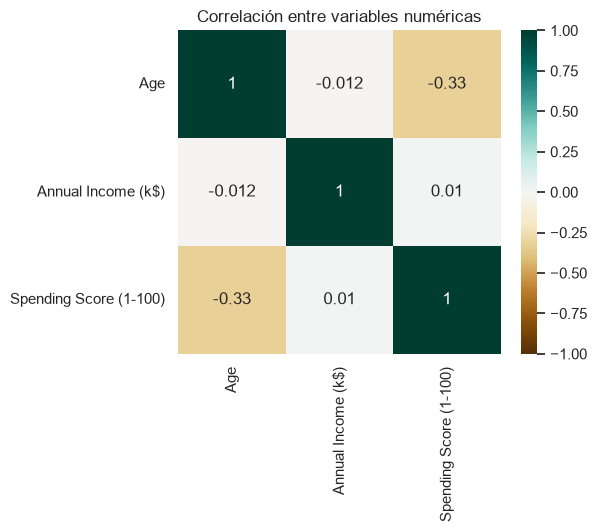

,Age,Annual Income (k$),Spending Score (1-100)
Age,1.000,-0.012,-0.327
Annual Income (k$),-0.012,1.000,0.010
Spending Score (1-100),-0.327,0.010,1.000


In [3]:
corr = df[[AGE, INCOME, SPENDING]].corr().round(3)
fig, ax = plt.subplots(figsize=(5.2, 4.2))
sns.heatmap(corr, annot=True, cmap="BrBG", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlación entre variables numéricas")
plt.show()
corr

Age: vallas [-1.62, 79.38] -> 0 atípicos []
Annual Income (k$): vallas [-13.25, 132.75] -> 2 atípicos [137, 137]
Spending Score (1-100): vallas [-22.62, 130.38] -> 0 atípicos []


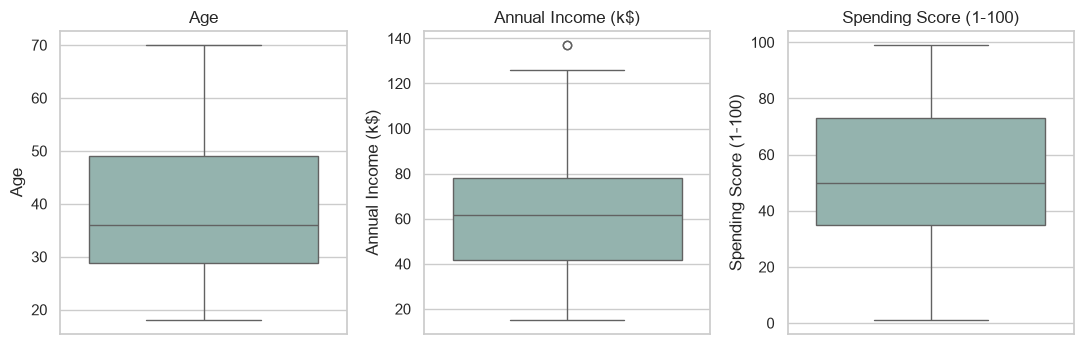

In [4]:
def atipicos_iqr(serie):
    q1, q3 = serie.quantile(0.25), serie.quantile(0.75)
    iqr = q3 - q1
    bajo, alto = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    fuera = serie[(serie < bajo) | (serie > alto)]
    return bajo, alto, fuera

for columna in (AGE, INCOME, SPENDING):
    bajo, alto, fuera = atipicos_iqr(df[columna])
    print(f"{columna}: vallas [{bajo:.2f}, {alto:.2f}] -> {len(fuera)} atípicos {fuera.tolist()}")

fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
for ax, columna in zip(axes, (AGE, INCOME, SPENDING)):
    sns.boxplot(y=df[columna], ax=ax, color="#8fb8b2")
    ax.set_title(columna)
plt.tight_layout()
plt.show()

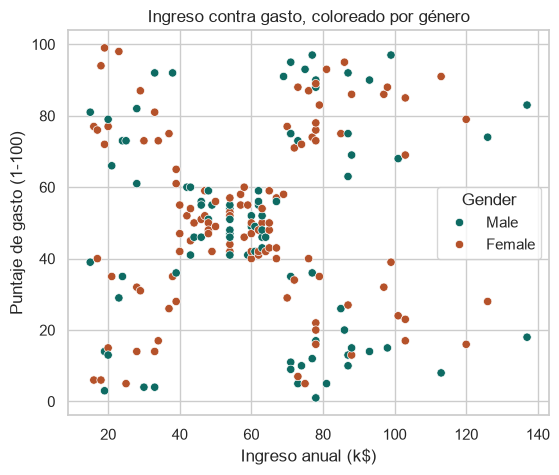

In [5]:
fig, ax = plt.subplots(figsize=(6.2, 5))
sns.scatterplot(data=df, x=INCOME, y=SPENDING, hue="Gender", ax=ax, palette=["#0e6b63", "#b5522a"])
ax.set_title("Ingreso contra gasto, coloreado por género")
ax.set_xlabel("Ingreso anual (k$)")
ax.set_ylabel("Puntaje de gasto (1-100)")
plt.show()

### Respuestas de la parte 1

**¿Qué variables son más adecuadas para segmentar clientes?**

Ingreso anual y puntaje de gasto. Describen capacidad de pago y comportamiento de compra, que es lo que marketing puede accionar. Su correlación lineal es 0.010: no hay una recta que las una, y por eso en el plano se ven nubes en lugar de una pendiente. La edad correlaciona -0.327 con el gasto y -0.012 con el ingreso. Aporta contexto (más adelante se ve que algunos segmentos son más jóvenes), pero al incluirla en K-Means la mejor silueta baja de 0.555 a 0.428. El género no entra en la distancia euclidiana; además, en el diagrama de dispersión hombres y mujeres se mezclan dentro de las mismas nubes. `CustomerID` solo identifica la fila.

**¿Se identifican valores atípicos?**

Con las vallas de Tukey (1.5 veces el rango intercuartílico) la edad y el puntaje de gasto no tienen atípicos. El ingreso tiene dos valores en 137 k$, por encima de la valla superior de 132.75. No son errores de captura: son la cola real de clientes de ingreso alto (uno gasta 83 y el otro 18). Se conservan, porque quitándolos se borraría justo la diferencia entre alto valor y potencial.

**¿Qué tipo de relaciones se observan entre las variables?**

Edad y gasto se mueven en sentido contrario: los puntajes altos se concentran en clientes más jóvenes. Edad e ingreso casi no se alinean. Ingreso y gasto tampoco tienen relación lineal. La estructura útil es de grupos: quien gana mucho puede gastar mucho o muy poco, y lo mismo ocurre en el ingreso bajo. Esa forma de cruz, no una correlación, es la que K-Means va a recoger.

## Parte 2. Preprocesamiento

K-Means usa distancia euclidiana. Antes de calcularla se estandarizan las variables con `StandardScaler` (media 0 y desviación estándar 1). Se comparan dos conjuntos: solo ingreso y gasto, y edad más ingreso y gasto.

In [6]:
conjuntos = {
    "ingreso_gasto": [INCOME, SPENDING],
    "edad_ingreso_gasto": [AGE, INCOME, SPENDING],
}

escalados = {}
for nombre, columnas in conjuntos.items():
    scaler = StandardScaler()
    escalados[nombre] = {
        "columnas": columnas,
        "X": scaler.fit_transform(df[columnas]),
        "media": scaler.mean_.round(3),
        "escala": scaler.scale_.round(3),
    }
    print(nombre)
    print("  media original :", dict(zip(columnas, scaler.mean_.round(3))))
    print("  desviación     :", dict(zip(columnas, scaler.scale_.round(3))))
    print("  media escalada :", escalados[nombre]["X"].mean(axis=0).round(6))
    print("  std escalada   :", escalados[nombre]["X"].std(axis=0).round(6))

ingreso_gasto
  media original : {'Annual Income (k$)': np.float64(60.56), 'Spending Score (1-100)': np.float64(50.2)}
  desviación     : {'Annual Income (k$)': np.float64(26.199), 'Spending Score (1-100)': np.float64(25.759)}
  media escalada : [-0. -0.]
  std escalada   : [1. 1.]
edad_ingreso_gasto
  media original : {'Age': np.float64(38.85), 'Annual Income (k$)': np.float64(60.56), 'Spending Score (1-100)': np.float64(50.2)}
  desviación     : {'Age': np.float64(13.934), 'Annual Income (k$)': np.float64(26.199), 'Spending Score (1-100)': np.float64(25.759)}
  media escalada : [-0. -0. -0.]
  std escalada   : [1. 1. 1.]


### Respuesta de la parte 2

**¿Por qué es necesario escalar las variables en K-Means?**

Porque el algoritmo asigna cada cliente al centroide más cercano y esa cercanía es euclidiana: suma diferencias al cuadrado. Si una variable tiene unidades más grandes o más dispersión, domina la suma y las demás casi no deciden el grupo. `StandardScaler` resta la media y divide por la desviación estándar, así que cada variable pesa lo mismo.

En este archivo el ingreso ya viene en miles de dólares (desviación 26.2) y el puntaje de gasto tiene una desviación muy parecida (25.8), así que entre esas dos el efecto numérico es moderado. Igual se escalan: es la condición para compararlas de forma justa. La edad tiene otra unidad y otra dispersión (13.9). Sin escalar, la comparación entre el modelo de dos variables y el de tres no sería válida.

## Parte 3. Método del codo

Se entrena K-Means para k de 1 a 10 y se grafica la inercia (suma de distancias al cuadrado dentro de cada grupo, WCSS). El codo es el k donde la curva deja de caer en picada. Para no elegirlo a ojo, se mide la distancia de cada punto a la recta que une el primer y el último k: el más alejado es el codo.

ingreso_gasto -> codo en k = 5


edad_ingreso_gasto -> codo en k = 4


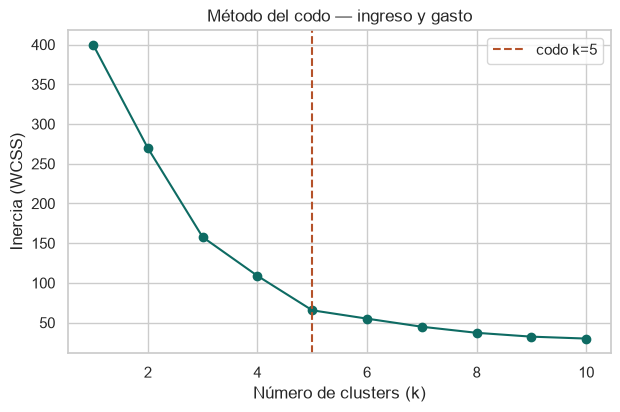

,k,inercia,silueta
0,1,400.0000,NaN
1,2,269.6910,0.3213
2,3,157.7040,0.4666
3,4,108.9213,0.4939
4,5,65.5684,0.5547
5,6,55.0573,0.5399
6,7,44.8648,0.5281
7,8,37.2282,0.4552
8,9,32.3923,0.4571
9,10,29.9819,0.4432


In [7]:
def entrenar(X, k):
    modelo = KMeans(n_clusters=k, init="k-means++", n_init=10, max_iter=300, random_state=RANDOM_STATE)
    modelo.fit(X)
    return modelo

def codo(ks, inercias):
    x = np.asarray(ks, dtype=float)
    y = np.asarray(inercias, dtype=float)
    x_n = (x - x.min()) / (x.max() - x.min())
    y_n = (y - y.min()) / (y.max() - y.min())
    inicio, fin = np.array([x_n[0], y_n[0]]), np.array([x_n[-1], y_n[-1]])
    linea = fin - inicio
    largo = np.linalg.norm(linea)
    distancias = []
    for i in range(len(x_n)):
        punto = np.array([x_n[i], y_n[i]])
        cruce = linea[0] * (inicio[1] - punto[1]) - (inicio[0] - punto[0]) * linea[1]
        distancias.append(abs(cruce) / largo)
    return int(ks[int(np.argmax(distancias))])

curvas = {}
for nombre, paquete in escalados.items():
    filas = []
    for k in range(1, 11):
        modelo = entrenar(paquete["X"], k)
        silueta = None
        if k >= 2:
            silueta = round(float(silhouette_score(paquete["X"], modelo.labels_)), 4)
        filas.append({"k": k, "inercia": round(float(modelo.inertia_), 4), "silueta": silueta})
    ks = [fila["k"] for fila in filas]
    inercias = [fila["inercia"] for fila in filas]
    curvas[nombre] = {"filas": filas, "codo": codo(ks, inercias)}
    print(nombre, "-> codo en k =", curvas[nombre]["codo"])

elegida = curvas["ingreso_gasto"]
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot([f["k"] for f in elegida["filas"]], [f["inercia"] for f in elegida["filas"]], marker="o", color="#0e6b63")
ax.axvline(elegida["codo"], color="#b5522a", ls="--", label=f"codo k={elegida['codo']}")
ax.set_xlabel("Número de clusters (k)")
ax.set_ylabel("Inercia (WCSS)")
ax.set_title("Método del codo — ingreso y gasto")
ax.legend()
plt.show()
pd.DataFrame(elegida["filas"])

### Respuestas de la parte 3

**¿Por qué valores cercanos a cero indican mejor ajuste?**

La inercia suma, para todos los clientes, el cuadrado de la distancia a su centroide. Cerca de cero, los puntos quedaron pegados a su centro: dentro del grupo el ajuste es alto. No conviene perseguir el cero sin límite. Con k igual a 200 (un cluster por cliente) la inercia es cero y el modelo no resume nada. El codo separa la mejora real de ese sobreajuste.

**¿Cómo se identifica el punto óptimo de k?**

Se grafica la inercia de k = 1 a k = 10. El óptimo es el quiebre: la curva cae fuerte y después cada cluster nuevo recorta poco error. La distancia a la recta entre los extremos localiza ese quiebre en **k = 5** para ingreso y gasto. De k = 5 (inercia 65.6) a k = 10 (inercia 30.0) la caída ya es lenta comparada con el salto desde k = 1 (inercia 400).

## Parte 4. Coeficiente de silueta

Para cada k entre 2 y 10 se calcula la silueta media. El coeficiente de un cliente es (b − a) / max(a, b): *a* es la distancia media a los de su grupo y *b* es la distancia media al grupo vecino más cercano.

ingreso_gasto silueta máxima 0.5547 en k = 5 | codo en 5
edad_ingreso_gasto silueta máxima 0.4284 en k = 6 | codo en 4


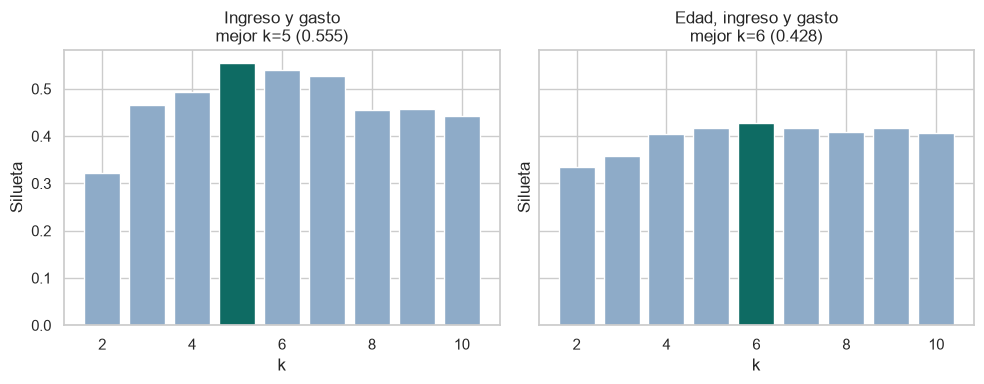

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, nombre, titulo in zip(
    axes,
    ("ingreso_gasto", "edad_ingreso_gasto"),
    ("Ingreso y gasto", "Edad, ingreso y gasto"),
):
    filas = [f for f in curvas[nombre]["filas"] if f["silueta"] is not None]
    mejor = max(filas, key=lambda f: f["silueta"])
    curvas[nombre]["mejor_silueta_k"] = mejor["k"]
    curvas[nombre]["mejor_silueta"] = mejor["silueta"]
    colores = ["#0e6b63" if f["k"] == mejor["k"] else "#8eabc8" for f in filas]
    ax.bar([f["k"] for f in filas], [f["silueta"] for f in filas], color=colores)
    ax.set_title(f"{titulo}\nmejor k={mejor['k']} ({mejor['silueta']:.3f})")
    ax.set_xlabel("k")
    ax.set_ylabel("Silueta")
    print(nombre, "silueta máxima", mejor["silueta"], "en k =", mejor["k"], "| codo en", curvas[nombre]["codo"])
plt.tight_layout()
plt.show()

### Respuestas de la parte 4

**¿Qué mide el coeficiente de silueta?**

Mide, al mismo tiempo, cohesión y separación. Para cada cliente compara qué tan cerca está de su propio grupo (*a*) y qué tan lejos está del grupo ajeno más próximo (*b*). El promedio de (b − a) / max(a, b) es la silueta del modelo. No mira solo si el grupo es compacto: también mira si está lejos de los demás.

**¿Qué significa un valor cercano a 1?**

Los clientes están juntos dentro de su segmento y lejos de los otros. Los grupos se distinguen con claridad. El 0.555 de este modelo no es 1, pero es claramente el mejor de la curva y, en datos reales de clientes, es una separación útil.

**¿Qué implica un valor cercano a 0 o negativo?**

Cerca de 0, la distancia al propio centro y al grupo vecino son parecidas: la frontera es débil y los segmentos se pisan. Un valor negativo indica que hay clientes más cerca de otro grupo que del suyo; la asignación es pobre.

**¿Coincide el valor óptimo de k con el método del codo?**

Sí, en el conjunto elegido. Codo y silueta señalan **k = 5** para ingreso y gasto (silueta 0.5547). Bajar de 5 mezclaría, dentro del mismo nivel de ingreso, a quien gasta mucho con quien gasta poco. Subir de 5 parte nubes que ya son compactas y la silueta baja (0.540 en k = 6, 0.528 en k = 7).

En el conjunto con edad, los dos criterios no coinciden: el codo cae en k = 4 y la silueta máxima es 0.428 en k = 6, por debajo de 0.555. Por eso el modelo final no usa la edad. La edad se conserva como descripción de cada segmento, no como variable de la distancia.

## Parte 5. Modelo K-Means

Se entrena un pipeline `StandardScaler` + `KMeans(k=5)` sobre ingreso y gasto. El pipeline es lo que se guarda: así, un cliente nuevo se escala con la misma media y la misma desviación del entrenamiento.

In [9]:
K = 5
pipeline = Pipeline(
    steps=[
        ("scaler", StandardScaler()),
        ("kmeans", KMeans(n_clusters=K, init="k-means++", n_init=10, max_iter=300, random_state=RANDOM_STATE)),
    ]
)
df["cluster"] = pipeline.fit_predict(df[[INCOME, SPENDING]])
scaler = pipeline.named_steps["scaler"]
kmeans = pipeline.named_steps["kmeans"]
centroides = pd.DataFrame(
    scaler.inverse_transform(kmeans.cluster_centers_),
    columns=[INCOME, SPENDING],
)
centroides.index.name = "cluster"
silueta_final = silhouette_score(scaler.transform(df[[INCOME, SPENDING]]), df["cluster"])
print(f"Inercia = {kmeans.inertia_:.2f} | silueta = {silueta_final:.4f}")
print("Tamaño de cada cluster:")
print(df["cluster"].value_counts().sort_index())
centroides.round(2)

Inercia = 65.57 | silueta = 0.5547
Tamaño de cada cluster:
cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


,Annual Income (k$),Spending Score (1-100)
cluster,,
0,55.30,49.52
1,86.54,82.13
2,25.73,79.36
3,88.20,17.11
4,26.30,20.91


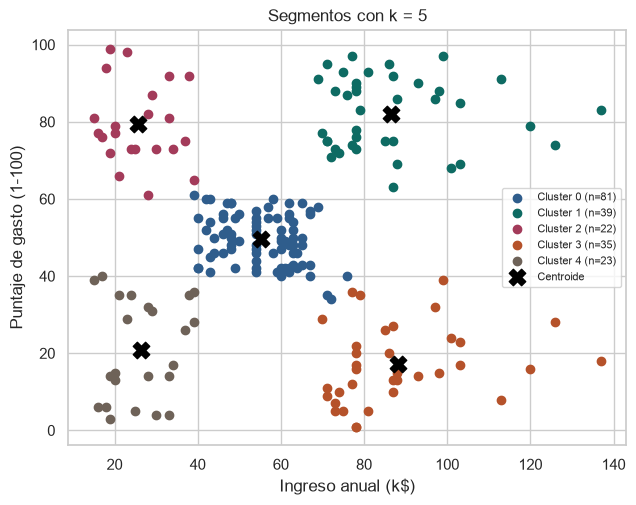

In [10]:
paleta = {0: "#2f5d8c", 1: "#0e6b63", 2: "#a33b5a", 3: "#b5522a", 4: "#6e6258"}
fig, ax = plt.subplots(figsize=(7.2, 5.4))
for cluster, parte in df.groupby("cluster"):
    ax.scatter(parte[INCOME], parte[SPENDING], s=36, color=paleta[cluster], label=f"Cluster {cluster} (n={len(parte)})")
ax.scatter(centroides[INCOME], centroides[SPENDING], c="black", marker="X", s=140, label="Centroide")
ax.set_xlabel("Ingreso anual (k$)")
ax.set_ylabel("Puntaje de gasto (1-100)")
ax.set_title("Segmentos con k = 5")
ax.legend(fontsize=8)
plt.show()

In [11]:
resumen = df.groupby("cluster").agg(
    n=("CustomerID", "size"),
    edad_media=(AGE, "mean"),
    ingreso_medio=(INCOME, "mean"),
    gasto_medio=(SPENDING, "mean"),
    ingreso_min=(INCOME, "min"),
    ingreso_max=(INCOME, "max"),
    gasto_min=(SPENDING, "min"),
    gasto_max=(SPENDING, "max"),
).round(2)
mujeres = df.assign(mujer=(df["Gender"] == "Female").astype(int)).groupby("cluster")["mujer"].mean().mul(100).round(1)
resumen["mujeres_pct"] = mujeres
resumen

,n,edad_media,ingreso_medio,gasto_medio,ingreso_min,ingreso_max,gasto_min,gasto_max,mujeres_pct
cluster,,,,,,,,,
0,81,42.72,55.30,49.52,39,76,34,61,59.3
1,39,32.69,86.54,82.13,69,137,63,97,53.8
2,22,25.27,25.73,79.36,15,39,61,99,59.1
3,35,41.11,88.20,17.11,70,137,1,39,45.7
4,23,45.22,26.30,20.91,15,39,3,40,60.9


### Respuestas de la parte 5

Los números de cluster son una etiqueta arbitraria de K-Means. Lo que identifica al grupo es su centroide.

| Cluster | Perfil | n | Ingreso (k$) | Gasto | Edad media |
| --- | --- | ---: | ---: | ---: | ---: |
| 0 | Promedio | 81 | 55.3 | 49.5 | 42.7 |
| 1 | Alto valor | 39 | 86.5 | 82.1 | 32.7 |
| 2 | Entusiastas | 22 | 25.7 | 79.4 | 25.3 |
| 3 | Potencial | 35 | 88.2 | 17.1 | 41.1 |
| 4 | Bajo valor | 23 | 26.3 | 20.9 | 45.2 |

**¿Qué representa cada cluster?**

- **0, promedio.** Ingreso y gasto pegados a la media del mall (60.6 k$ y 50.2 de gasto). Es el grupo grande: 81 personas, 40.5% de la base.
- **1, alto valor.** Ingreso alto y gasto alto. Edad media 32.7, concentrada entre 27 y 40 años. Son quienes ya convierten capacidad de pago en compra.
- **2, entusiastas.** Gasto casi tan alto como el de alto valor (79 frente a 82) con un ingreso de solo 25.7 k$. Son los más jóvenes (edad media 25.3).
- **3, potencial.** Ingreso tan alto como el de alto valor (88 k$) y gasto de 17, parecido al de bajo valor. La capacidad está; la compra no.
- **4, bajo valor.** Ingreso bajo y gasto bajo. Edad media 45.2. Aportan poco ticket.

**¿Qué diferencias existen entre los grupos?**

La diferencia no es el género: en todos los segmentos las mujeres son alrededor de la mitad (entre 46% y 61%). La diferencia está en la combinación ingreso-gasto. Alto valor y potencial comparten ingreso y se separan por el gasto (82 contra 17). Entusiastas y bajo valor comparten ingreso bajo y se separan por el gasto (79 contra 21). El promedio no se extreme en ninguna de las dos. La edad acompaña: entusiastas y alto valor son más jóvenes; promedio, potencial y bajo valor pasan de 40 años.

## Parte 6. Interpretación de negocio

Los cinco clusters caben en los perfiles que pide el taller. El quinto no es un promedio repetido: es el cliente que gasta mucho con un ingreso ajustado. Forzarlo dentro de "bajo valor" escondería a quien sí compra.

**Mayor oportunidad de crecimiento: clientes con potencial (cluster 3).** Tienen ingreso alto y gasto bajo. Cada punto de gasto que se les active vale más que el mismo esfuerzo sobre quien ya gasta mucho, o sobre quien tiene poco margen de ingreso.

### Estrategias por segmento

**Clientes de alto valor.** Programa de lealtad con beneficios de experiencia, no solo descuento. Acceso anticipado y atención personalizada. Venta cruzada de categorías premium, cuidando el margen. Conviene medir recompra y ticket, no la respuesta a cupones.

**Clientes con potencial.** Primero entender la barrera: surtido, experiencia, horario o relevancia. Campañas de descubrimiento y prueba, con asesoría, sin descuentos agresivos que abaraten la marca. El indicador es el segundo ticket: que la visita se vuelva hábito.

**Clientes promedio.** Comunicación de valor y promociones de temporada, moderadas. Puntos para subir la frecuencia sin tocar el precio de lista. Recomendaciones de complemento sobre lo que ya compran. Cuidar lo básico: filas, disponibilidad y precio claro.

**Clientes de bajo valor.** Formatos de entrada y presentaciones pequeñas. Canales digitales de bajo costo, no asesoría larga. Ofertas de tráfico separadas de la comunicación premium. No asignarles el mismo presupuesto de retención que al alto valor.

**Clientes entusiastas.** Combos, cuotas y premio por frecuencia. Promociones con fecha de cierre, para que el precio pleno siga existiendo. Sirven como referidos. Hay que vigilar el margen de cada campaña para no subsidiar todo el ticket.

**¿Qué segmento representa mayor oportunidad de crecimiento?**

El de potencial. Son 35 clientes (17.5%) con un centroide de 88 k$ de ingreso y 17 de gasto. Su ingreso se parece al del alto valor y su gasto al del bajo valor. Cerrar parte de esa brecha mueve más dinero que empujar a los entusiastas, que ya gastan cerca de su techo, o a los de bajo valor, cuyo ingreso limita el ticket.

## Persistencia del modelo

Se guarda el pipeline completo. `joblib` conserva el escalador ajustado y los centroides. Al cargar el archivo, `predict` escala al cliente nuevo y lo asigna al centroide más cercano. No hay que volver a calcular medias a mano.

In [12]:
salida = ROOT / "models" / "kmeans_mall.joblib"
salida.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(
    {
        "pipeline": pipeline,
        "features": [INCOME, SPENDING],
        "k": K,
        "random_state": RANDOM_STATE,
    },
    salida,
)
cargado = joblib.load(salida)
nuevo = pd.DataFrame([{INCOME: 95, SPENDING: 18}])
cluster_nuevo = int(cargado["pipeline"].predict(nuevo)[0])
print("Archivo:", salida.name)
print("Cliente de prueba (ingreso 95, gasto 18) -> cluster", cluster_nuevo)
print("Ese cluster tiene centroide:")
print(centroides.loc[cluster_nuevo].round(2))

Archivo: kmeans_mall.joblib
Cliente de prueba (ingreso 95, gasto 18) -> cluster 3
Ese cluster tiene centroide:
Annual Income (k$)        88.20
Spending Score (1-100)    17.11
Name: 3, dtype: float64


## Parte 7. Despliegue interactivo

El enunciado pide una aplicación con cuatro funciones: ver el método del codo, ver los clusters, ingresar un cliente nuevo y clasificarlo. Eso está en `streamlit_app.py`, que carga este mismo `joblib`.

Se abre con `streamlit run streamlit_app.py`. El menú recorre exploración, preprocesamiento, codo, silueta, segmentos, negocio y la clasificación de un cliente nuevo. Edad y género se piden en la ficha y no entran en la distancia, por la decisión de la parte 1 y la parte 4.

El detalle de arranque y de Streamlit Community Cloud está en `README.md`.